In [1]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# TensorFlow ≥2.0 is required
import tensorflow as tf
from tensorflow import keras
assert tf.__version__ >= "2.0"

import keras.backend as K

from keras.utils.vis_utils import plot_model

# Common imports
import numpy as np
import os

# to make this notebook's output stable across runs
np.random.seed(42)
tf.random.set_seed(42)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

In [2]:
# Try to make GPU memory allocation dynamic, so it doesn't slow down/crash
physical_devices = tf.config.list_physical_devices('GPU')
try:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
    # config = tf.compat.v1.ConfigProto()
    # config.gpu_options.allow_growth = True
    # session = tf.compat.v1.Session(config=config)
except:
    print('oh no.')
  # Invalid device or cannot modify virtual devices once initialized.
    pass

In [3]:
# Check and test that TensorFlow can use GPU/CUDA cores

# tf.debugging.set_log_device_placement(True)

print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

# Create some tensors
a = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
b = tf.constant([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
c = tf.matmul(a, b)

tf.debugging.set_log_device_placement(False)
print(c)

Num GPUs Available:  1
tf.Tensor(
[[22. 28.]
 [49. 64.]], shape=(2, 2), dtype=float32)


In [4]:
physical_devices

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [5]:
#The goal of this project is to use a Generative Adversarial Network (GAN) to generate supplemental data for histopathological brain tumor samples, providing a solution to the relative scarcity of publicly available brain tumor data for machine learning and other
# scientific endeavors.
#
# For the time being, we focus on creating a proof of concept that works on smaller iomages while we figure out how to work around the large filesizes of the Digital Brain Tunmour Atlas' histopathological slide images.
# The GAN should be context-agnostic, so it should work on any images of brain tumors.
# As such, for the proof of concept model, we use images from Kaggle's Brain Tumor MRI Dataset, which combines several datasets into one place: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset?resource=download
# This data must be preprocessed, since images from different sources are of difference sizes.

In [6]:
pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install imutils

Note: you may need to restart the kernel to use updated packages.


In [8]:
pip install visualkeras --upgrade

Note: you may need to restart the kernel to use updated packages.


In [9]:
pip install pydot

Note: you may need to restart the kernel to use updated packages.


In [10]:
# import numpy as np 
from tqdm import tqdm
import cv2
# import os
import imutils

# change this to wherever your images are located
DATASET_PATH = r'C:/Users/Aihara/Desktop/Temporary Jupter Stuff/Kaggle - Brain Tumor MRI Dataset'


def crop_img(img):
	"""
	Finds the extreme points on the image and crops the rectangular out of them
	"""
	gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	gray = cv2.GaussianBlur(gray, (3, 3), 0)

	# threshold the image, then perform a series of erosions +
	# dilations to remove any small regions of noise
	thresh = cv2.threshold(gray, 45, 255, cv2.THRESH_BINARY)[1]
	thresh = cv2.erode(thresh, None, iterations=2)
	thresh = cv2.dilate(thresh, None, iterations=2)

	# find contours in thresholded image, then grab the largest one
	cnts = cv2.findContours(thresh.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
	cnts = imutils.grab_contours(cnts)
	c = max(cnts, key=cv2.contourArea)

	# find the extreme points
	extLeft = tuple(c[c[:, :, 0].argmin()][0])
	extRight = tuple(c[c[:, :, 0].argmax()][0])
	extTop = tuple(c[c[:, :, 1].argmin()][0])
	extBot = tuple(c[c[:, :, 1].argmax()][0])
	ADD_PIXELS = 0
	new_img = img[extTop[1]-ADD_PIXELS:extBot[1]+ADD_PIXELS, extLeft[0]-ADD_PIXELS:extRight[0]+ADD_PIXELS].copy()
	
	return new_img
	
if __name__ == "__main__":
	training = DATASET_PATH + "/Training"
	testing = DATASET_PATH + "/Testing"
	training_dir = os.listdir(training)
	testing_dir = os.listdir(testing)
	IMG_SIZE = 256

	for dir in training_dir:
		save_path = 'cleaned/Training/'+ dir
		path = os.path.join(training,dir)
		image_dir = os.listdir(path)
		for img in image_dir:
			image = cv2.imread(os.path.join(path,img))
			new_img = crop_img(image)
			new_img = cv2.resize(new_img,(IMG_SIZE,IMG_SIZE))
			if not os.path.exists(save_path):
				os.makedirs(save_path)
			cv2.imwrite(save_path+'/'+img, new_img)
	
	for dir in testing_dir:
		save_path = 'cleaned/Testing/'+ dir
		path = os.path.join(testing,dir)
		image_dir = os.listdir(path)
		for img in image_dir:
			image = cv2.imread(os.path.join(path,img))
			new_img = crop_img(image)
			new_img = cv2.resize(new_img,(IMG_SIZE,IMG_SIZE))
			if not os.path.exists(save_path):
				os.makedirs(save_path)
			cv2.imwrite(save_path+'/'+img, new_img)

In [11]:
# # mini-batch standard deviation layer (code borrowed from https://stackoverflow.com/questions/63122680/correct-way-to-apply-minibatch-standard-deviation-to-keras-gan-layer This implements the same steps as described in the textbook.)

# def minibatch_std_layer(layer, group_size=4):

#     group_size = K.minimum(4, layer.shape[0])
#     shape = layer.shape

#     minibatch = K.reshape(layer,(group_size, -1, shape[1], shape[2]))
#     minibatch -= tf.reduce_mean(minibatch, axis=0, keepdims=True)
#     minibatch = tf.reduce_mean(K.square(minibatch), axis = 0)
#     minibatch = K.square(minibatch + 1e-8) #epsilon=1e-8
#     minibatch = tf.reduce_mean(minibatch, axis=[1,2], keepdims=True)
#     minibatch = K.tile(minibatch,[group_size, 1, shape[2]])
#     return K.concatenate([layer, minibatch], axis=1)

In [12]:
# Code to load images borrowed from https://github.com/masoudnick/Brain-Tumor-MRI-Classification/blob/main/Brain_Tumor_Classification.ipynb

# Change these to where your cleaned data are located
CLEANED_TRAINING_PATH = "C:\\Users\\Aihara\\Desktop\\Temporary Jupter Stuff\\cleaned\\Training"
CLEANED_TESTING_PATH = "C:\\Users\\Aihara\\Desktop\\Temporary Jupter Stuff\\cleaned\\Testing"

labels = ['glioma', 'meningioma', 'notumor', 'pituitary']

x_train = [] # training images.
y_train  = [] # training labels.
x_test = [] # testing images.
y_test = [] # testing labels.

image_size = 200


for label in labels:
    trainPath = os.path.join(CLEANED_TRAINING_PATH,label)
    for file in tqdm(os.listdir(trainPath)):
        image = cv2.imread(os.path.join(trainPath, file),0) # load images in gray.
        image = cv2.bilateralFilter(image, 2, 50, 50) # remove images noise.
        image = cv2.applyColorMap(image, cv2.COLORMAP_BONE) # produce a pseudocolored image.
        image = cv2.resize(image, (image_size, image_size)) # resize images into 200*200.
        x_train.append(image)
        y_train.append(labels.index(label))
    
    testPath = os.path.join(CLEANED_TESTING_PATH,label)
    for file in tqdm(os.listdir(testPath)):
        image = cv2.imread(os.path.join(testPath, file),0)
        image = cv2.bilateralFilter(image, 2, 50, 50)
        image = cv2.applyColorMap(image, cv2.COLORMAP_BONE)
        image = cv2.resize(image, (image_size, image_size))
        x_test.append(image)
        y_test.append(labels.index(label))


x_train = np.array(x_train, dtype=np.float32) / 255.0 # normalize Images into range 0 to 1.
x_test = np.array(x_test, dtype=np.float32) / 255.0

# By default, Tensorflow uses float32.You have to convert your data to tf.float32.
# X = tf.cast(yourDATA, tf.float32) 

# x_train = tf.cast(x_train, tf.float32)
# x_test = tf.cast(x_test, tf.float32)

print(x_train.shape)
print(x_test.shape)

100%|██████████| 300/300 [00:01<00:00, 183.12it/s]


(5712, 200, 200, 3)
(1311, 200, 200, 3)


In [13]:
# These images are (200, 200, 3) each, since they have 3 channels (assuming they're Red, Blue, and Green channels).

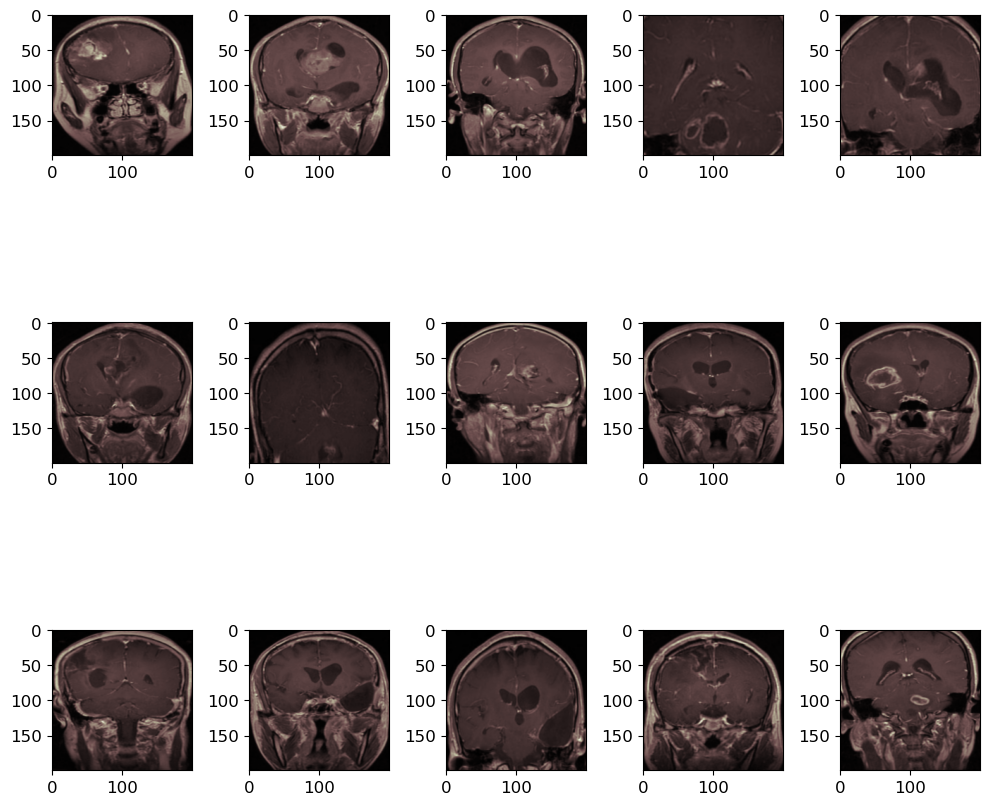

In [14]:
# Checking on the images

images = [x_train[i] for i in range(15)]
fig, axes = plt.subplots(3, 5, figsize = (10, 10))
axes = axes.flatten()
for img, ax in zip(images, axes):
    ax.imshow(img)
plt.tight_layout()
plt.show()

(200, 200)
0.8980392


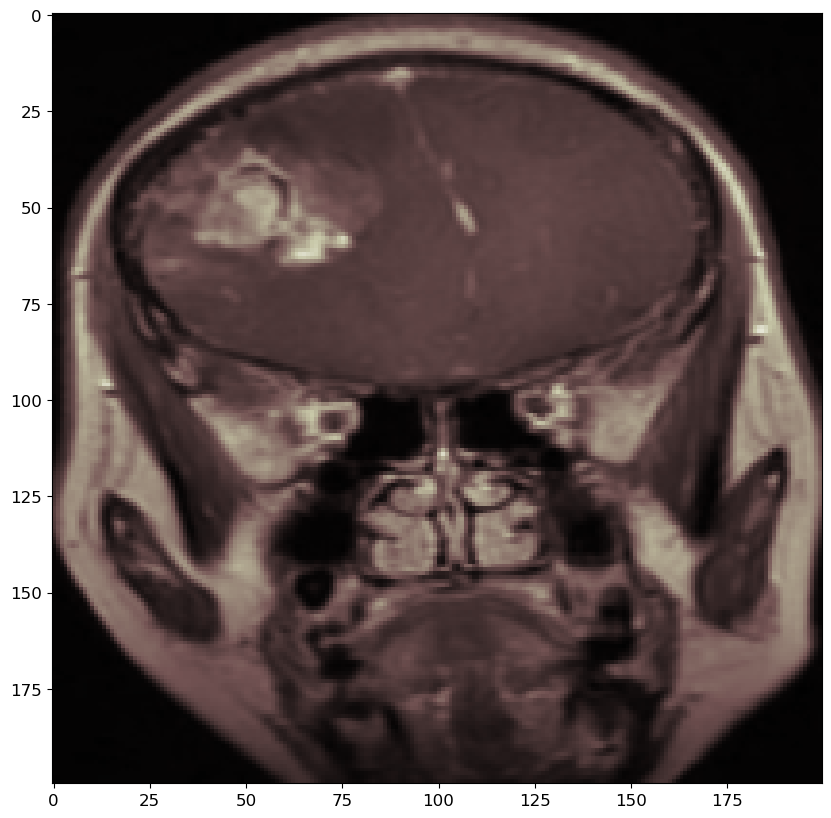

In [15]:
print(x_train[0][:,:,0].shape)
fig, axes = plt.subplots(1, 1, figsize = (10, 10))
axes.imshow(x_train[0])
print(np.max(x_train[0]))
plt.show()

In [16]:
# # Create some random Gaussian noise. This will be used as the basis for the other noise inputs.
# gnoise = tf.random.normal(shape=128)
# B1 = keras.layers.Dense(128)
# gnoise_one = B1(gnoise)


# B1.get_weights()
# # factors1 = tf.transpose(factors1)
# # gnoise1 = tf.multiply(gnoise1, factors1)
# # x = tf.add(x, gnoise1)

In [17]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = np.squeeze(images, axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image)#, cmap='bone')
        # plt.imshow(image[:,:,::-1])
        plt.axis("off")

In [18]:
################################################################
# Here we define some custom layers for the GAN/StyleGAN
################################################################

In [19]:
# mini-batch std dev layer option #2
class MinibatchStdDevLayer(tf.keras.layers.Layer):
  
    def __init__(self, num_outputs):
        super(MinibatchStdDevLayer, self).__init__()
        self.num_outputs = num_outputs
  
    def build(self, input_shape):
        self.kernel = self.add_weight("kernel", shape = [int(input_shape[-1]), self.num_outputs])

    def call(self, inputs):
        mean = K.mean(inputs, axis=0, keepdims=True)
        mean_sq_diff = K.mean(K.square(inputs - mean), axis=0, keepdims=True) + 1e-8
        mean_pix = K.mean(K.sqrt(mean_sq_diff), keepdims=True)
        shape = K.shape(inputs)
        output = K.tile(mean_pix, [shape[0], shape[1], shape[2], 1])
        return K.concatenate([inputs, output], axis = -1)

    # Define the output shape of the layer, since you're adding more information
    # for the discriminator to use
    def comput_output_shape(self, input_shape):
        input_shape = list(input_shape)
        input_shape[-1] += 1
        return tuple(input_shape)

In [20]:
# Define equalized learning rate for each dense layer.
# code borrowed from (https://stackoverflow.com/questions/60012406/how-may-i-do-equalized-learning-rate-with-tensorflow-2)
# Modified dense layers should re-scale all the weights down each time the layer
# is called, scaled down by sqrt of 2/number of layer inputs. 

class DenseEQ(keras.layers.Dense):
    """
    Standard dense layer but includes learning rate equilization
    at runtime as per Karras et al. 2017.

    Inherits Dense layer and overides the call method.
    """
    def __init__(self, **kwargs):
        if 'kernel_initializer' in kwargs:
            raise Exception("Cannot override kernel_initializer")
        super().__init__(kernel_initializer=tf.keras.initializers.RandomNormal(mean=0., stddev=1.), **kwargs)
        
    def build(self, input_shape):
        super().build(input_shape)
        # The number of inputs
        n = np.product([int(val) for val in input_shape[1:]])
        # He initialisation constant
        self.c = np.sqrt(2/n)
        
    def call(self, inputs):
        output = K.dot(inputs, self.kernel*self.c) # scale kernel
        if self.use_bias:
            output = K.bias_add(output, self.bias, data_format='channels_last')
        if self.activation is not None:
            output = self.activation(output)
        return output

In [21]:
# Define a layer type to add noise to the various places in the styleGAN where it needs to go.

# This type of layer will create some weights which will be applied to each copy of the Gaussian noise image.
# Therefore, the Gaussian noise vector should be upscaled to the desired sizes separately, and will be fed into
# these layers.
# The layer inputs should be:
#      x - layer to which to add the weighted noise filters. i.e., the "main" layer of the generator. dimensions (res, res, num_filters)
#      noise - the Gaussian noise vector, of dimensions (res, res, num_filters)
# 
# 
# 
# 
# 
# ##############################################################################################################################################
# 
# For some reason, when compiling the model, it runs into an error here: input_shape is apparently "NoneType," despite the layer being called
# with inputs as such later in the code: AddNoise()([x, noise])
#
# ##############################################################################################################################################

class AddNoise(keras.layers.Layer):
    def build(self, input_shape):
        n, h, w, c = input_shape[0]
        initializer = keras.initializers.RandomNormal(mean=0.0, stddev=1.0)
        self.b = self.add_weight(shape = [1, 1, 1, c], initializer = initializer, trainable = True, name = 'kernel')
        
    def call(self, inputs):
        x, noise = inputs
        output = x + self.b * noise
        return output

In [22]:
# Define AdaIN functions for styleGAN implementation
# Borrowed and modified from (https://keras.io/examples/generative/adain/)


def get_mean_std(x, epsilon=1e-5, axes = [1,2]):
    # axes = [1, 2]

    # Compute the mean and standard deviation of a tensor.
    mean, variance = tf.nn.moments(x, axes=axes, keepdims=True)
    standard_deviation = tf.sqrt(variance + epsilon)
    return mean, standard_deviation


def ada_in(style, content):
    """Computes the AdaIn feature map.

    Args:
        style: The style feature map. 
        content: The content feature map. 

    Returns:
        The AdaIN feature map.
    """
    content_mean, content_std = get_mean_std(content)
    style_mean, style_std = get_mean_std(style) #, axes = [0])
    t = style_std * (content - content_mean) / content_std + style_mean
    return t


In [87]:
# StyleGAN Generator
# Since styleGAN is a nonlinear model, we attempt to use the Keras Functional API in order to implement styleGAN techniques.
# The following lines of code consitute a generator that implements techniques from StyleGAN. Namely, the Mapping Network
# and the Synthesis Network.
# The Mapping Network takes the starting encoding and maps it to multiple vectors that control the style of the generated images
# at different scales, with the end result that generated images should have similar local structure as the training images at 
# all scales. The Synthesis network then incorporates these multiple vectors alongside gaussian noise via the Adaptive Instance
# Normalization functions/layers.

tf.random.set_seed(42)
np.random.seed(42)

# codings_size = 16
codings_size = 32

# MAPPING NETWORK - EIGHT-LAYER MLP FOR AFFINE TRANSFORMING THE ENCODINGS
ELMLP_input = keras.Input(shape=(codings_size,))
x = keras.layers.BatchNormalization()(ELMLP_input)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)
x = keras.layers.Dense(codings_size, activation='relu')(x)

# This is the style vector w which will be inserted to many other layers in the Synthesis Network part of the generator.
ELMLP_output_w = keras.layers.Dense(codings_size, activation='relu')(x)




# SYNTHESIS NETWORK - FOR IMPLEMENTING STYLEGAN FEATURES
# For this, we need several blocks, each which function to upsample the output from the previous input/layer.


# BLOCK #1
block_one_in = keras.Input(shape=(codings_size,))
x = keras.layers.Dense(50*50*128)(block_one_in)
x = keras.layers.Reshape([50, 50, 128])(x)

# Add Gaussian Noise with previous input
# This should be done in the following way:
#     Create a single feature map of Gaussian noise.
#     Broadcast this feature map to all feature maps of the given level.
#     Scale the noise using per-feature scaling factors.
#
# For this purpose, the AddNoise layer has been created. It will take in the "main" layer, x, and the generated Gaussian noise.
# So we first create the layer to take in some Gaussian noise from a vector:
basenoise = keras.Input(shape=(codings_size,))

gnoise1 = keras.layers.Dense(50*50)(basenoise)
gnoise1 = keras.layers.Reshape([50,50,1])(gnoise1)

# Add gaussian noise to x. Now we can pass x along to the rest of the layers.
x = AddNoise()([x, gnoise1])



# Send latent mapping w through Affine Transformation
# Note that there should be as many nodes in the dense layer here as there are filters in the previous layer.
# UPDATE - It seems that the style vector should have one scale term and one bias term for EACH feature map in x.
# So the Affine transofmation should not just map the style vector w from codings_size -> 128, it should map it 
# to codings_size -> (2, 128).
# We do this first by passing wp through the affine layer, and then re-shaping the output to the desired dimensions.
#      There's no indication that this is how to do it, or even that this will work, but it's the best i've got right now.
A1 = keras.layers.Dense(2*128)
wp = A1(ELMLP_output_w)
wp = keras.layers.Reshape([2,128])(wp)

# Pass previous two results to AdaIN.
x = ada_in(style = wp, content = x)

# Convolutional layer, keep same size
x = keras.layers.Conv2D(128, kernel_size=3, strides=1, padding="SAME", activation="relu")(x)

# Apply another Gaussian Noise after the convolution
gnoise2 = keras.layers.Dense(50*50)(basenoise)
gnoise2 = keras.layers.Reshape([50,50,1])(gnoise2)
x = AddNoise()([x, gnoise2])

# one more adaIN
A2 = keras.layers.Dense(2*128)
wp2 = A2(ELMLP_output_w)
wp2 = keras.layers.Reshape([2,128])(wp2)
x = ada_in(style = wp2, content = x)

# Upsample the image, using the same kind of 2DConvTranspose as in the normal DCGAN.
# This upsamples the image to 100x100 pixels, and 64 filters/feature maps.
block_one_output = keras.layers.Conv2DTranspose(64, kernel_size=5, strides=2, padding="SAME",
                                 activation="relu")(x)

# And that's the Block! Now we'll add more until we reach our desired resolution of 200x200 pixels:




# BLOCK #2
x = keras.layers.Conv2D(64, kernel_size=3, strides=1, padding="SAME", activation="relu")(block_one_output)
gnoise3 = keras.layers.Dense(100*100)(basenoise)
gnoise3 = keras.layers.Reshape([100,100,1])(gnoise3)
x = AddNoise()([x, gnoise3])
A3 = keras.layers.Dense(2*64)
wp3 = A3(ELMLP_output_w)
wp3 = keras.layers.Reshape([2,64])(wp3)
x = ada_in(style = wp3, content = x)
x = keras.layers.Conv2D(64, kernel_size=3, strides=1, padding="SAME", activation="relu")(x)
gnoise4 = keras.layers.Dense(100*100)(basenoise)
gnoise4 = keras.layers.Reshape([100,100,1])(gnoise4)
x = AddNoise()([x, gnoise4])
A4 = keras.layers.Dense(2*64)
wp4 = A4(ELMLP_output_w)
wp4 = keras.layers.Reshape([2,64])(wp4)
x = ada_in(style = wp4, content = x)
block_two_out = keras.layers.Conv2DTranspose(3, kernel_size=5, strides=2, padding="SAME",
                                 activation="tanh")(x)

# Reserve this for checking model structure.  
SynthNet = keras.Model(inputs = (ELMLP_input, block_one_in, basenoise), outputs = block_two_out, name="SynthNet")

import visualkeras
# visualkeras.layered_view(SynthNet, legend=True)
SynthNet.summary()

Model: "SynthNet"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_11 (InputLayer)           [(None, 32)]         0                                            
__________________________________________________________________________________________________
batch_normalization_5 (BatchNor (None, 32)           128         input_11[0][0]                   
__________________________________________________________________________________________________
dense_51 (Dense)                (None, 32)           1056        batch_normalization_5[0][0]      
__________________________________________________________________________________________________
dense_52 (Dense)                (None, 32)           1056        dense_51[0][0]                   
___________________________________________________________________________________________

In [86]:
# for layer in SynthNet.layers:
#     print(layer.output_shape)

In [90]:
# Do the inputs work properly?
# For some reason, just specifying shape=(codings_size,) isn't enough.
# It won't run unless it's (1, codings_size).
# I have no clue why that is.
batch_size=32

noisew = tf.random.normal(shape=(batch_size, codings_size))
# noisew0 = tf.reshape(noisew[0], (1, codings_size))
# noisew = tf.repeat(noisew, batch_size, axis=0)
        
# Noise for the main images
noise = tf.random.normal(shape=(batch_size, codings_size))
        
# Noise for the gaussian noise vector
noiseg = tf.random.normal(shape=(batch_size, codings_size))
# noiseg0 = tf.reshape(noiseg[0], (1, codings_size))
# noiseg = tf.repeat(noiseg, batch_size, axis=0)
        
print(noisew.shape)
print(noisew0.shape)
print(noise.shape)
print(noiseg.shape)
print(noiseg0.shape)
    
generated_images = SynthNet(inputs=(noisew, noise, noiseg))
plot_multiple_images(generated_images, 8)

(32, 32)
(1, 32)
(32, 32)
(32, 32)
(1, 32)


InvalidArgumentError: required broadcastable shapes [Op:Mul]

In [34]:
tf.random.set_seed(42)
np.random.seed(42)

noisew = tf.random.normal(shape=(1, codings_size))
noisew = tf.repeat(noisew,32, axis=0)
noisew

<tf.Tensor: shape=(32, 32), dtype=float32, numpy=
array([[ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409],
       [ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409],
       [ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409],
       ...,
       [ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409],
       [ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409],
       [ 0.3274685 , -0.8426258 ,  0.3194337 , ..., -0.5256233 ,
         0.32410017,  0.02545409]], dtype=float32)>

In [35]:
# DISCRIMINATOR
# The structure of the discriminator will not change compared to the previous model. It's only rewritten here in the functional form
# to be consistent with the StyleGAN-style generator above.

disc_in = keras.Input(shape=(200, 200, 3))
x = keras.layers.Conv2D(64, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2),
                        input_shape=[200, 200, 3])(disc_in)
x =  keras.layers.BatchNormalization()(x)
x =  keras.layers.Conv2D(128, kernel_size=5, strides=2, padding="SAME",
                        activation=keras.layers.LeakyReLU(0.2))(x)
x = keras.layers.BatchNormalization()(x)
x = MinibatchStdDevLayer(4)(x)
x = keras.layers.Flatten()(x)
disc_out = DenseEQ(units=1, activation="sigmoid")(x)

discriminator_func = keras.Model(inputs = disc_in, outputs = disc_out, name="Discriminator")
# visualkeras.layered_view(discriminator_func, legend=True)
# discriminator_func.summary()

In [36]:
# for layer in SynthNet.layers:
#     print(layer.output_shape)

In [37]:
# for layer in discriminator_func.layers:
#     print(layer.output_shape)
    
# SynthNet.input

In [38]:
# import visualkeras
# visualkeras.layered_view(discriminator, legend=True)

In [39]:
# Since the discriminator is a binary classifier (real/fake image), we can set the loss to binary_crossentropy.
# Similarly, since the GAN as a whole is a binary classifier, we can do the same.
# 
# Once the GAN is created, we must appropriately compile/determine which parts of the model are trainable or not.
# Since "trainable" is only taken into account while compiling, we first compile the discriminator assuming it will be trained. Then, we switch it so that it cannot be trained once the complete GAN is compiled.  
# This way, when we train the GAN, we can separate the training of the discriminator and the generator during each pass - the discriminator is first trained on a combo of real/fake data, then the discriminator is switched to non-trainable, and the
# generator is trained to try and outsmart the discriminator.

In [40]:
# Here we'll put together the generator and the discriminator.

discriminator_func.trainable=True
discriminator_func.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])
discriminator_func.trainable=False

stylegan = keras.models.Model(inputs=SynthNet.input, outputs=discriminator_func(SynthNet.output))
stylegan.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])
# stylegan.summary()

In [41]:
# In order to train a GAN, we must use a custom training loop similar to the one defined in the HOA/textbook.
# To do this, the training is split into two phases for each training pass/epoch.
# In phase 1, the discriminator is trained on a a combined dataset of real images and images built by the generator using Gaussian noise as input.
# In phase 2, the generator is trained by feeding Gaussian noise to the GAN itself. Now, the images from the generator are tested using the newly-trained discriminator from phase 1. 

In [42]:
# Reshape and rescale the data to account for the tanh activation function in 
# the generator.
# If we use sigmoid instead, we don't need to rescale/readjust later and can 
# comment this part out.
# I think we need to undo this rescaling when plotting/displaying the generated 
# images, since some will have negative values that get clipped when plotted by imshow().

# This should be fine to use for both the DCGAN and the StyleGAN models.


# Turn off for sigmoid activation in generator.
x_train_dcgan = x_train.reshape(-1, 200, 200, 3) * 2. - 1.
# x_train_dcgan = x_train

In [43]:
batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(x_train_dcgan).shuffle(1000)
dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(1)

In [82]:
def train_stylegan(gan, dataset, batch_size, codings_size, n_epochs=50):
  
  for epoch in range(n_epochs):
    print ("Epoch {}/{}".format(epoch +1, n_epochs))
    
    
    # Try keeping the input noise for style and gaussian noise vectors constant across the epoch.
    # We'll try making them change each batch later, but this seems like a reasonable approach.
    
    # The inputs to SynthNet are generically noise of size 32, 32, and 32.
    # The model layers are defined as (None, 32), so that the first dimension can be
    # flexible depending on the size of the batch passed to the layer.
    # However, we intially only gave a batch size for the noise that's going into the main pipeline.
    # It looks like SynthNet gets mad when we only pass the size-32 noise vectors to train_on_batch,
    # since it expects a size-32 noise vector for EACH image going through the pipeline.
    # -> Try using tf.repeat to copy the size-32 vector 32 times for each, and see if it works.
    
    
    # Noise for the style vectors
    # I have no idea why it only works if the shape is [1, codings_size].
    noisew = tf.random.normal(shape=(1, codings_size))
    noisew = tf.repeat(noisew, 32, axis=0)
    noisew0 = tf.reshape(noisew[0], (1, codings_size))
    
    
    # Noise for the gaussian noise vector
    # I have no idea why it only works if the shape is [1, codings_size].
    noiseg = tf.random.normal(shape=(1, codings_size))
    noiseg = tf.repeat(noiseg, 32, axis=0)
    noiseg0 = tf.reshape(noiseg[0], (1, codings_size))
    
    for X_batch in dataset:

        # PHASE 1 - TRAINING THE DISCRIMINATOR
        # As before, we must provide some random noise vector of size 
        # codings_size to the generator so it can create images:
        
        # Noise for the main images
        noise = tf.random.normal(shape=(batch_size, codings_size))
        
        generated_images = SynthNet(inputs=(noisew0, noise, noiseg0))

        # Combined dataset of both real and newly generated fake images 
        X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
        y1 = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)

        # Actually training the discriminator on the above data.
        discriminator_func.trainable = True
        discriminator_func.train_on_batch(X_fake_and_real, y1)

        # PHASE 2 - TRAINING THE GENERATOR

        # Generating noise to feed into the GAN
        noise = tf.random.normal(shape=[batch_size, codings_size])
        y2 = tf.constant([[1.]] * batch_size)

        # Actually training the generator by having the newly-trained discriminator classify its attempts as real/fake images. 
        discriminator_func.trainable = False
        stylegan.train_on_batch((noisew, noise, noiseg), y2)

    # Turn off for sigmoid activation in generator.
    # Undo the reshaping/scaling we neede for the tanh activation in the generator.
    fixed_img = (generated_images + 1.)/2.
    plot_multiple_images(fixed_img, 8)
    # plot_multiple_images(generated_images, 8)        
    plt.show()

In [83]:
train_stylegan(stylegan, dataset, batch_size, codings_size, n_epochs=10)

Epoch 1/10


ValueError: in user code:

    C:\Users\Aihara\anaconda3\lib\site-packages\keras\engine\training.py:853 train_function  *
        return step_function(self, iterator)
    C:\Users\Aihara\anaconda3\lib\site-packages\keras\engine\training.py:842 step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    C:\Users\Aihara\anaconda3\lib\site-packages\tensorflow\python\distribute\distribute_lib.py:1286 run
        return self._extended.call_for_each_replica(fn, args=args, kwargs=kwargs)
    C:\Users\Aihara\anaconda3\lib\site-packages\tensorflow\python\distribute\distribute_lib.py:2849 call_for_each_replica
        return self._call_for_each_replica(fn, args, kwargs)
    C:\Users\Aihara\anaconda3\lib\site-packages\tensorflow\python\distribute\distribute_lib.py:3632 _call_for_each_replica
        return fn(*args, **kwargs)
    C:\Users\Aihara\anaconda3\lib\site-packages\keras\engine\training.py:835 run_step  **
        outputs = model.train_step(data)
    C:\U

In [ ]:
# Next step (4/21/23)
# We need to figure out how to put together this generator and discriminator together in a gan and train things accordingly.
# Remember, for the compiling/training, we need the discriminator to be trainable in the first half of each training pass, but
# non-trainable for the second pass, where the generator is training.
# First, we'll start without any sort of experience replay, just to see if the model will even run at all.

In [ ]:
# Notes (4/21/23 (evening))
# Generator and discriminator have been put together.
# StyleGAN runs, but locks up at epoch 19/32.
# On another attempt, it finished running completely? Something may be messing with the stability/execution speed of the model.
# Perhaps there's an issue with the gradients? Maybe RMSprop isn't the best for this...? Could always play around with the kwargs for rmsprop.
# Also, try Adam again.
# Also, need to figure out how to properly implement the learning Gaussian Noise layers in the generator.